# 3. 坏消息更吓人（GJR）+ 用"标准化意外"算 VaR（FHS）

**这一本要回答的问题：** 仓库最后选定的正式 VaR 模型叫 **FHS-GJR，窗口 W = 1000**。这个名字里有两样东西：
- **GJR**：一种 GARCH，承认"跌比涨更让市场紧张"。
- **FHS**（过滤历史模拟）：用 GJR 算出"明天的天气"（波动率），再用历史上"意外的形状"算尾部。

这一本把两样东西拆开，各自用真实数据讲清楚，最后亲手复现仓库的第一天预测。

In [1]:
from learn_utils import *
from scipy.stats import norm, t as student_t
from mre.models.garch import fit_garch, fhs_var_es, standardized_quantile
from mre.risk.var import historical_var, historical_es

cfg, asset_rets, port = load_portfolio()
r = port
V = cfg.portfolio_value

## 第 1 步：直觉——跌了之后，第二天更不平静吗？

用数据直接问：把"今天跌超过 1%"的日子和"今天涨超过 1%"的日子分开，看**第二天**平均动多大。

In [2]:
def after_big_moves(threshold=0.01):
    tomorrow = r.shift(-1).abs()                     # 第二天动了多大（这里看"之后"只是为了描述历史，不是预测）
    down, up = r < -threshold, r > threshold
    print(f"今天跌超过 {threshold:.1%} 的日子：{down.sum():>4} 天，第二天平均 |收益| = {tomorrow[down].mean():.2%}")
    print(f"今天涨超过 {threshold:.1%} 的日子：{up.sum():>4} 天，第二天平均 |收益| = {tomorrow[up].mean():.2%}")
    print(f"所有日子的平均 |收益| = {r.abs().mean():.2%}")

after_big_moves(0.01)

今天跌超过 1.0% 的日子： 408 天，第二天平均 |收益| = 0.98%
今天涨超过 1.0% 的日子： 417 天，第二天平均 |收益| = 0.71%
所有日子的平均 |收益| = 0.59%


跌和涨的"幅度"差不多，可跌完之后第二天明显更动荡。这在金融里叫**杠杆效应**（leverage effect）：股价下跌 → 公司的负债相对股本变"重" → 风险变大；再加上恐慌情绪，跌比涨更能激起波动。

🎛️ 把门槛改成 2% 再看一次（直接改上面最后一行的 `0.01`，或者用下面的滑块）。

In [3]:
play(after_big_moves, examples=[{"threshold": 0.02}],
     threshold=(0.005, 0.03, 0.0025))

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ threshold = 0.02
今天跌超过 2.0% 的日子：  92 天，第二天平均 |收益| = 1.55%
今天涨超过 2.0% 的日子：  66 天，第二天平均 |收益| = 1.32%
所有日子的平均 |收益| = 0.59%


## 第 2 步：GJR——给坏消息多加一份

第 2 本里的 GARCH 对"涨 3%"和"跌 3%"一视同仁，因为它只看收益的**平方**。GJR 只改了一个地方：

> **新的估计 = ω + (α + γ × [今天是不是跌了]) × 今天冲击的平方 + β × 旧的估计**

- `[今天是不是跌了]`：跌了就是 1，涨了就是 0。
- **γ（gamma）**：坏消息的"额外加成"。γ > 0 就说明跌比涨更推高波动率。

下面在仓库**第一次**拟合用的数据上（前 1000 天，2006-01 到 2009-12，正好是 W = 1000）分别拟合 GARCH-t 和 GJR-t：

In [4]:
train = r.iloc[:1000].values                      # 第一个预测日 2009-12-23 之前的 1000 天
garch = fit_garch(train, dist="t", vol="garch")
gjr = fit_garch(train, dist="t", vol="gjr")
print(f"训练期：{r.index[0].date()} 到 {r.index[999].date()}")
print(f"GARCH-t: alpha={garch.alpha:.3f}  beta={garch.beta:.3f}")
print(f"GJR-t  : alpha={gjr.alpha:.3f}  gamma={gjr.gamma:.3f}  beta={gjr.beta:.3f}")
print(f"\nGJR 里：涨的日子，冲击的权重 = alpha = {gjr.alpha:.3f}")
print(f"        跌的日子，冲击的权重 = alpha + gamma = {gjr.alpha + gjr.gamma:.3f}")

训练期：2006-01-04 到 2009-12-22
GARCH-t: alpha=0.077  beta=0.918
GJR-t  : alpha=0.000  gamma=0.124  beta=0.929

GJR 里：涨的日子，冲击的权重 = alpha = 0.000
        跌的日子，冲击的权重 = alpha + gamma = 0.124


在这 1000 天里，GJR 估出来 α 基本是 0：**涨的日子几乎不推高明天的波动率，推高波动率的全是跌的日子。** 这正是第 1 步在数据里看到的现象，只不过现在被模型"量化"成了一个参数。

### 画出来："新闻冲击曲线"

假设今天之前一切正常（波动率在长期水平），今天突然涨或跌了 x%，模型对明天波动率的估计是多少？

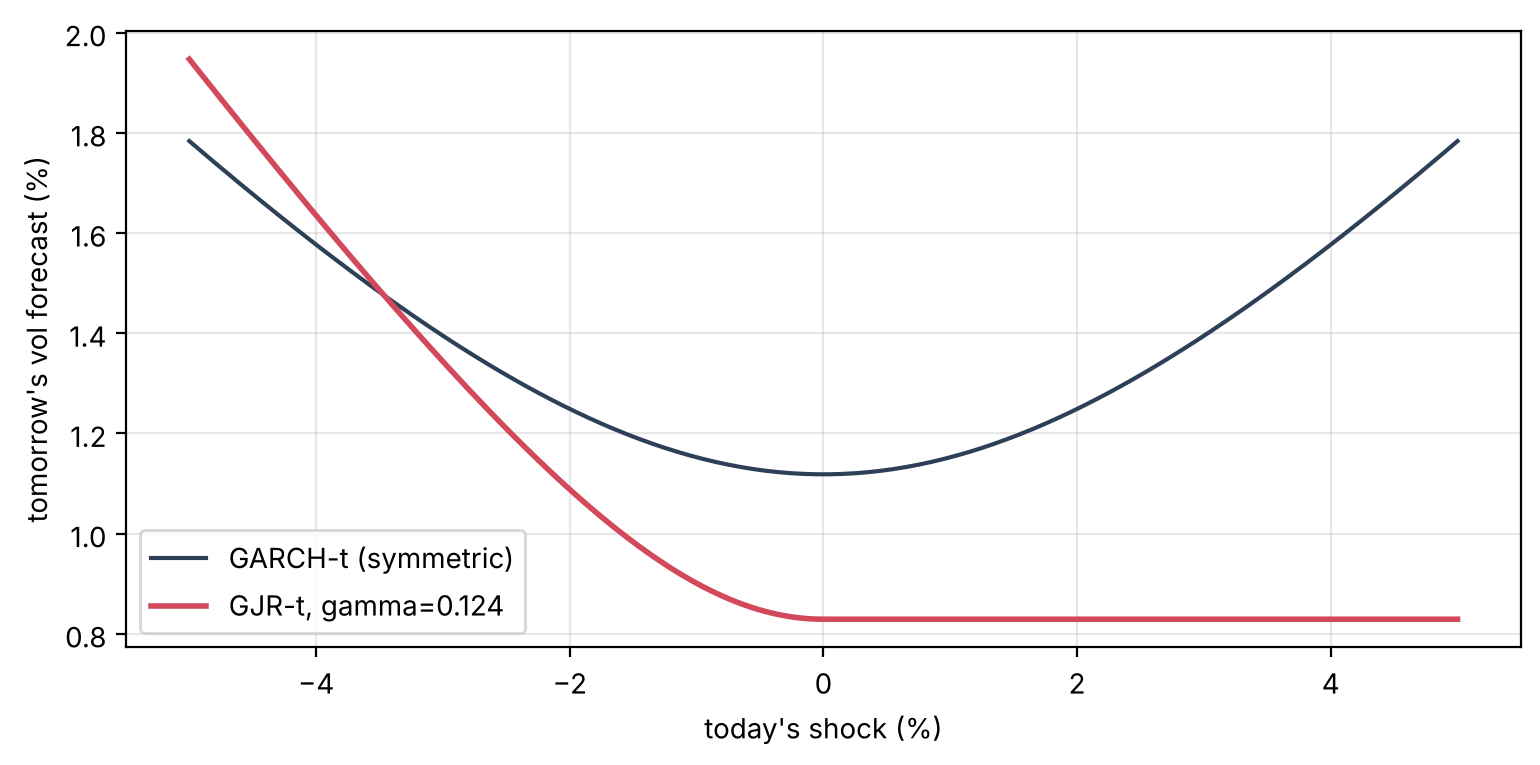

In [5]:
def news_impact(gamma_override=None):
    g = gjr.gamma if gamma_override is None else gamma_override
    x = np.linspace(-0.05, 0.05, 201)                      # 今天的冲击：-5% 到 +5%
    def curve(f, gamma):
        s2_base = f.omega / (1 - f.alpha - f.beta - 0.5 * gamma)   # 从长期水平出发
        return np.sqrt(f.omega + (f.alpha + gamma * (x < 0)) * x**2 + f.beta * s2_base)
    fig, ax = plt.subplots()
    ax.plot(x * 100, curve(garch, 0.0) * 100, color="#2e4057", label="GARCH-t (symmetric)")
    ax.plot(x * 100, curve(gjr, g) * 100, color="#d1495b", lw=2, label=f"GJR-t, gamma={g:.3f}")
    ax.set_xlabel("today's shock (%)"); ax.set_ylabel("tomorrow's vol forecast (%)")
    ax.legend(); plt.show()

news_impact()

GARCH 的曲线左右对称；GJR 的曲线**右边几乎是平的、左边陡**。

🎛️ 把 γ 拖到 0，GJR 会变成什么样？（`gamma_override` 只是改图里的 γ，不会重新拟合模型。为了不让长期水平变成无穷大，γ 最大只到 0.14。）

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ gamma_override = 0.0


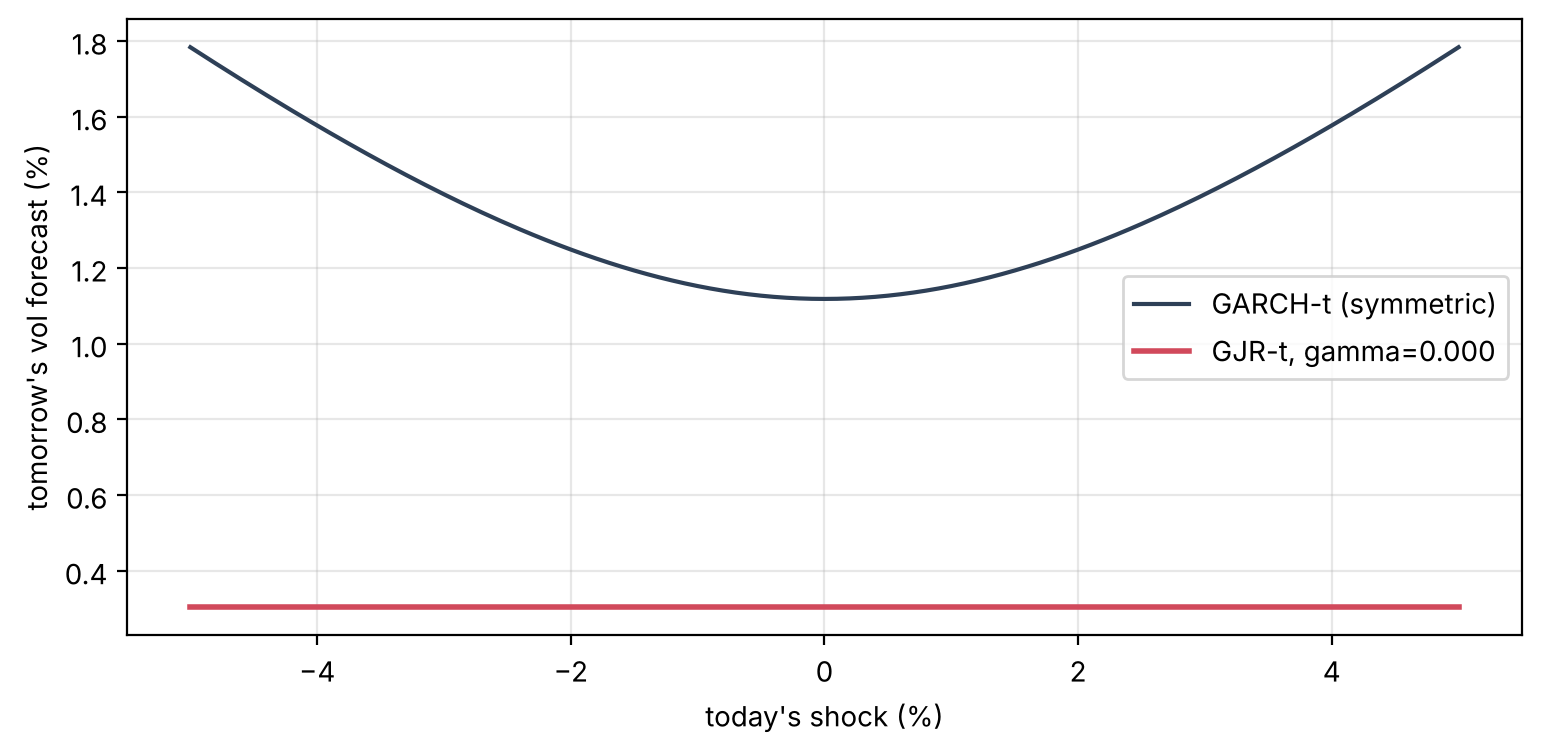

In [6]:
play(news_impact, examples=[{"gamma_override": 0.0}],
     gamma_override=(0.0, 0.14, 0.01))

在 Phase 3b 的滚动回测里（W = 500），GJR 每 21 天重新拟合一次。看看 2009–2025 年 γ 一直是正的吗：

gamma 中位数 0.191，最小 0.046，最大 0.311；gamma > 0 的天数占比 100%


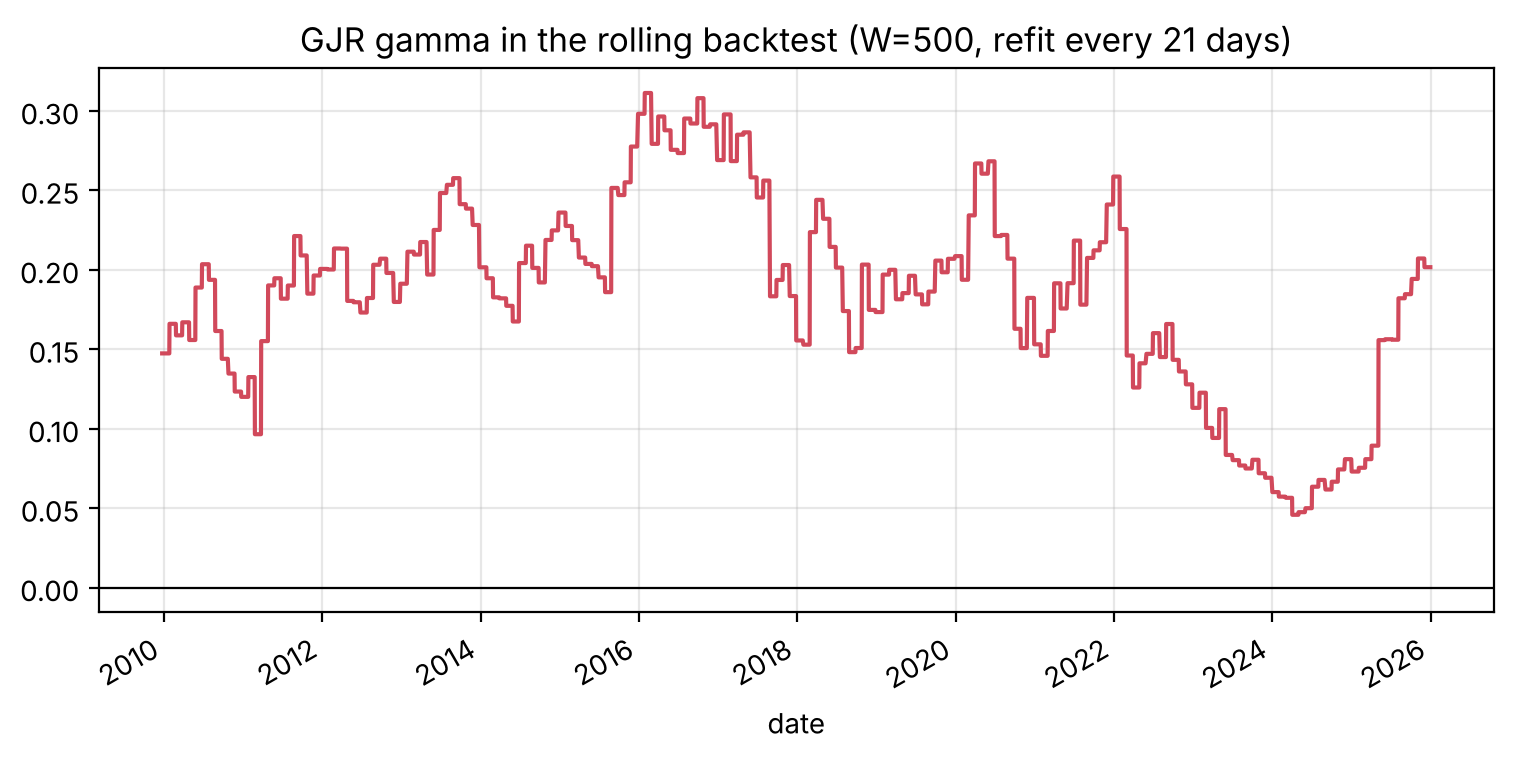

In [7]:
p3b = pd.read_csv(ROOT / "reports" / "phase3b_primary_forecasts.csv.gz", parse_dates=["date"])
g = p3b[p3b["model"] == "FHS (GJR-t filter)"].set_index("date")["gamma"]
print(f"gamma 中位数 {g.median():.3f}，最小 {g.min():.3f}，最大 {g.max():.3f}；gamma > 0 的天数占比 {(g > 0).mean():.0%}")
ax = g.plot(color="#d1495b", title="GJR gamma in the rolling backtest (W=500, refit every 21 days)")
ax.axhline(0, color="black", lw=0.8); plt.show()

## 第 3 步：FHS 的直觉——"标准化意外"

问题：2008 年 10 月的一天跌 3% 和 2017 年的一天跌 3%，意义完全不一样。前者在当时"很正常"，后者是"见鬼了"。直接把它们放进同一个历史样本里比较不公平。

FHS 的办法很简单：**每天的收益除以当天模型估计的波动率**，得到

> **z = (今天收益 − 平均收益) ÷ 今天的波动率估计**

z 可以理解为"今天的意外是几个标准差"。z = −3 就是"比平时预期的波动多跌了 3 倍"。不管在 2008 还是 2017，z = −3 的"惊吓程度"是一样的，所以这些 z 可以放在一起比较。

下面用刚才的 GJR-t（前 1000 天）把收益变成 z，对比一下：

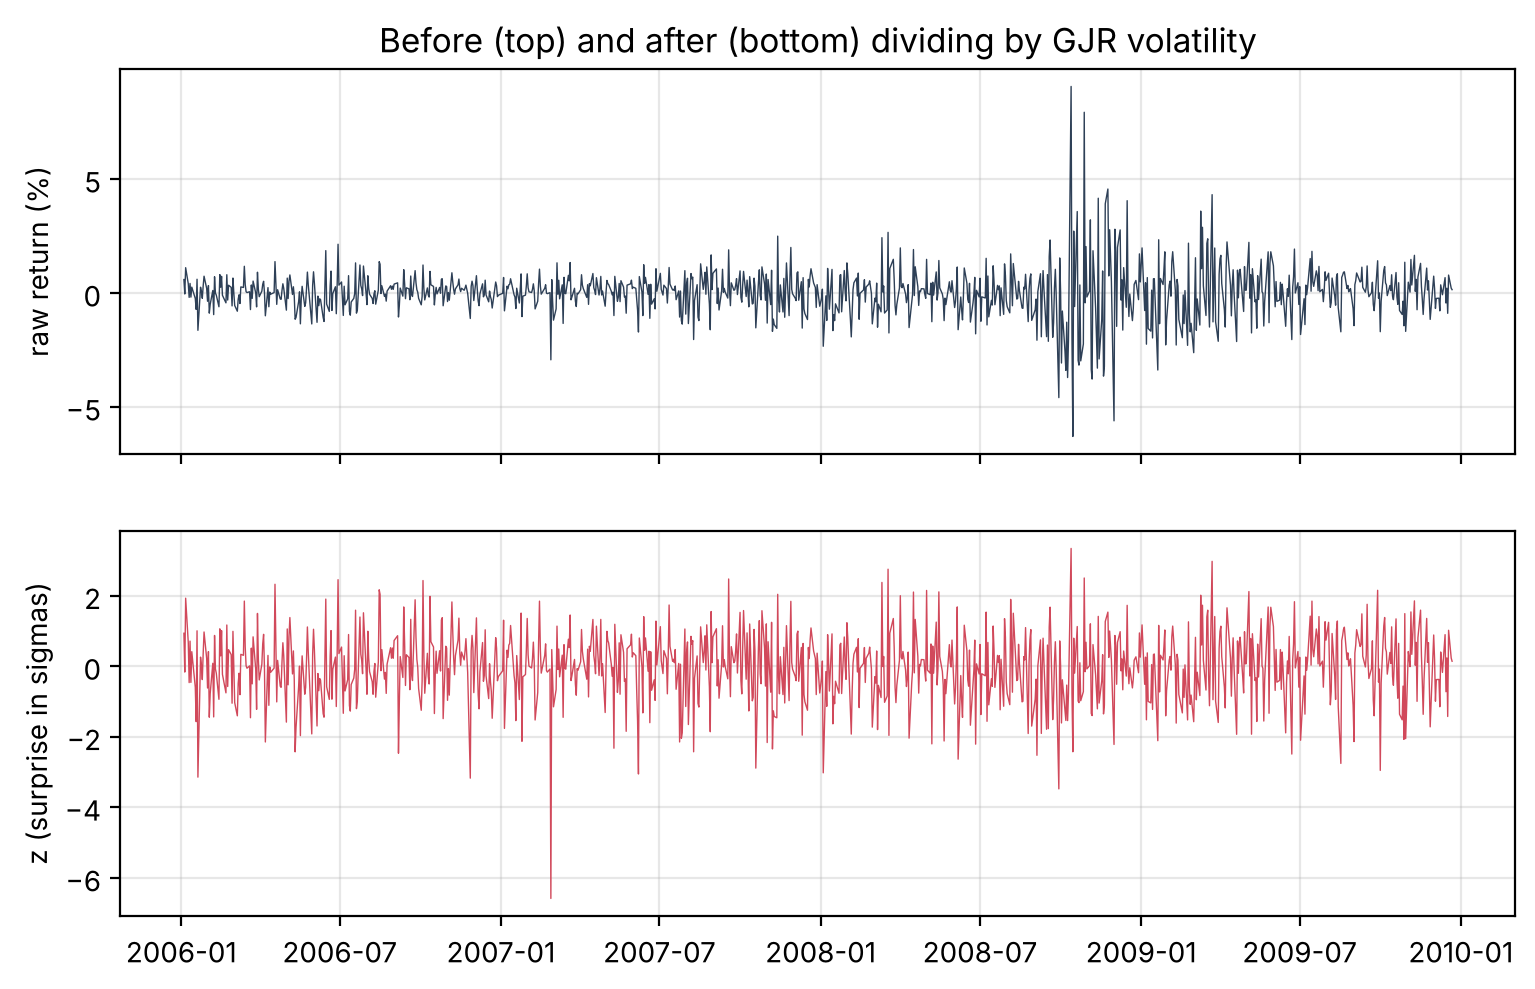

原始收益的标准差：前 250 天 0.57%，2008-09 到 2008-12 2.63%
z 的标准差：      前 250 天 0.94，  2008-09 到 2008-12 1.14


In [8]:
z = pd.Series(gjr.std_resid, index=r.index[:1000])        # 仓库 fit_garch 直接给出标准化残差 z
raw = r.iloc[:1000]
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(raw.index, raw * 100, lw=0.5, color="#2e4057"); axes[0].set_ylabel("raw return (%)")
axes[1].plot(z.index, z, lw=0.5, color="#d1495b"); axes[1].set_ylabel("z (surprise in sigmas)")
axes[0].set_title("Before (top) and after (bottom) dividing by GJR volatility"); plt.show()
print(f"原始收益的标准差：前 250 天 {raw.iloc[:250].std():.2%}，2008-09 到 2008-12 {raw['2008-09':'2008-12'].std():.2%}")
print(f"z 的标准差：      前 250 天 {z.iloc[:250].std():.2f}，  2008-09 到 2008-12 {z['2008-09':'2008-12'].std():.2f}")

上图：2008 年那段"山"非常明显；下图：除以波动率之后，"山"基本被削平了，z 在不同年份看起来差不多。

**FHS 的两步：**
1. 用 GJR 估出**明天**的波动率 σ（"明天的天气"）。
2. 在过去 W 天的 z 里数出最惨的 1%（"意外的形状"，就像第 1 本排卡片一样，只是卡片换成了 z）。
3. 明天的 VaR ≈ σ × (z 的第 1% 分位数，变成正数)。

好处：σ 跟得上市场（不像历史模拟那么迟钝），尾巴的形状又直接来自数据（不用假设正态或 t 分布）。

## 第 4 步：z 的尾巴到底有多肥？

如果 z 完全服从正态分布，它的 1% 分位数应该是 −2.326。来看看真实的 z：

z 的 1.0% 分位数：
  真实数据（FHS 用的）: -2.531
  正态分布           : -2.326
  t 分布 (nu= 8.6)  : -2.495


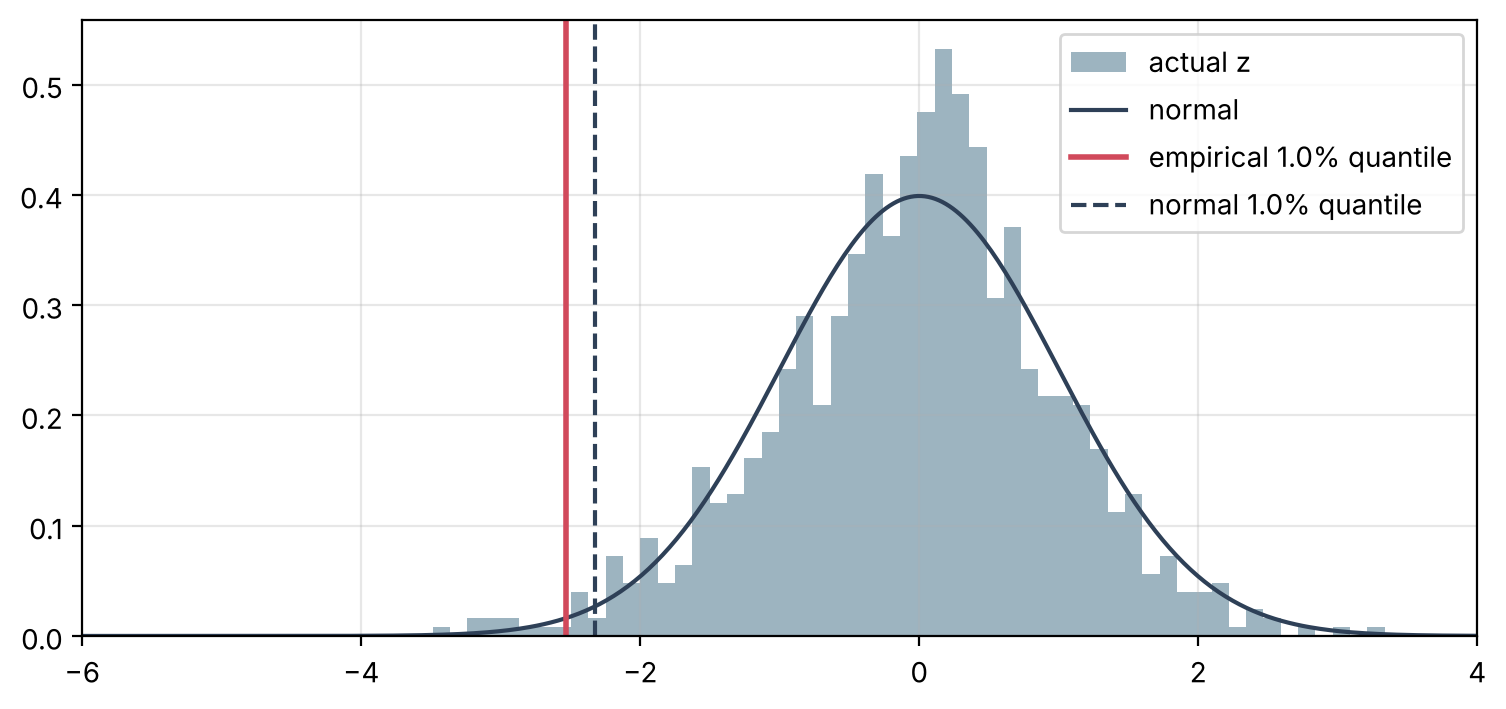

In [9]:
def tail_shapes(alpha=0.99):
    p = 1 - alpha
    q_emp = np.quantile(z, p)                                 # 数卡片
    q_norm = norm.ppf(p)                                      # 正态的说法
    q_t = standardized_quantile(p, "t", gjr.nu)               # t 分布（自由度 = 拟合出来的 nu）的说法
    print(f"z 的 {p:.1%} 分位数：")
    print(f"  真实数据（FHS 用的）: {q_emp:6.3f}")
    print(f"  正态分布           : {q_norm:6.3f}")
    print(f"  t 分布 (nu={gjr.nu:4.1f})  : {q_t:6.3f}")
    fig, ax = plt.subplots()
    ax.hist(z, bins=80, density=True, color="#9db4c0", label="actual z")
    xs = np.linspace(-6, 4, 400)
    ax.plot(xs, norm.pdf(xs), color="#2e4057", label="normal")
    ax.axvline(q_emp, color="#d1495b", lw=2, label=f"empirical {p:.1%} quantile")
    ax.axvline(q_norm, color="#2e4057", ls="--", label=f"normal {p:.1%} quantile")
    ax.set_xlim(-6, 4); ax.legend(); plt.show()

tail_shapes(0.99)

🎛️ 换不同的置信水平看看：在 95% 附近，三种说法差别大吗？在 99.5% 呢？

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ alpha = 0.95
z 的 5.0% 分位数：
  真实数据（FHS 用的）: -1.751
  正态分布           : -1.645
  t 分布 (nu= 8.6)  : -1.615


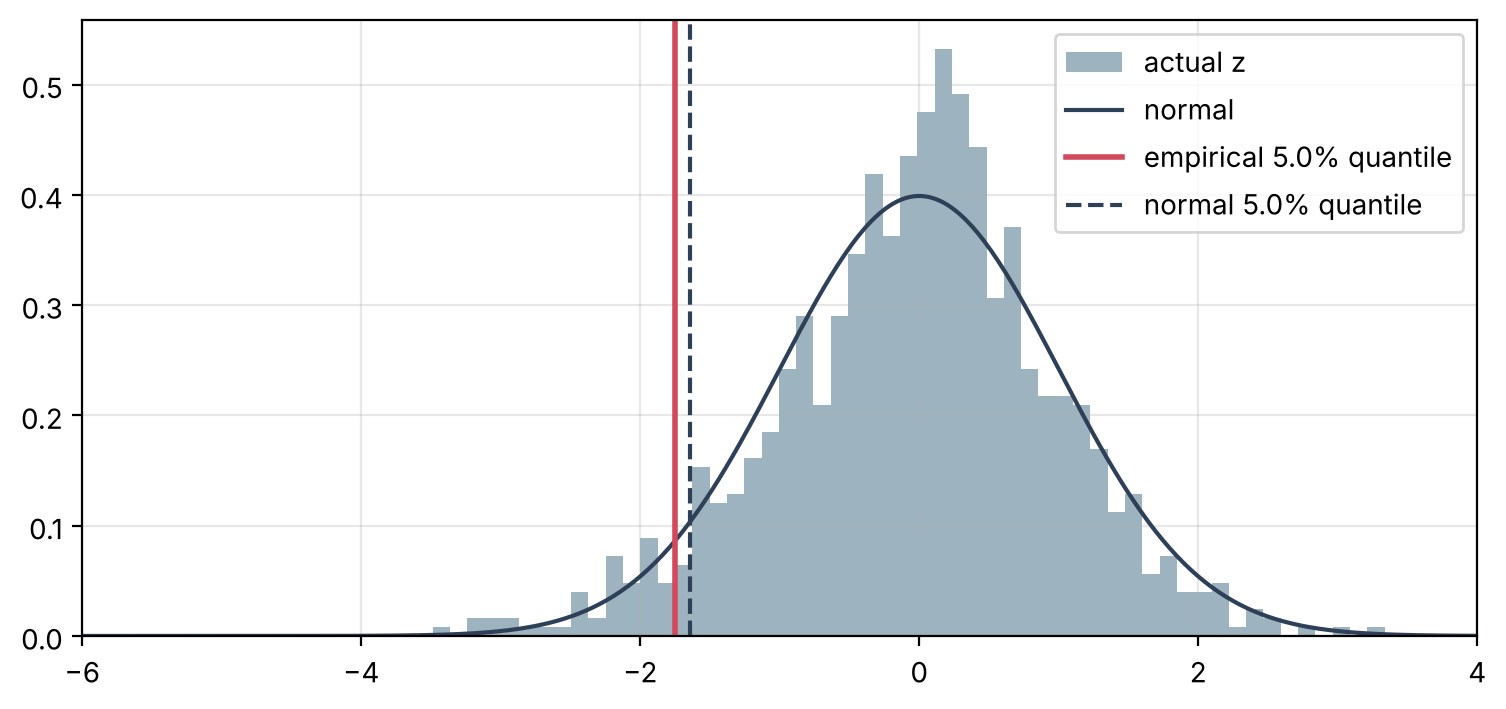


▶ alpha = 0.995
z 的 0.5% 分位数：
  真实数据（FHS 用的）: -3.027
  正态分布           : -2.576
  t 分布 (nu= 8.6)  : -2.880


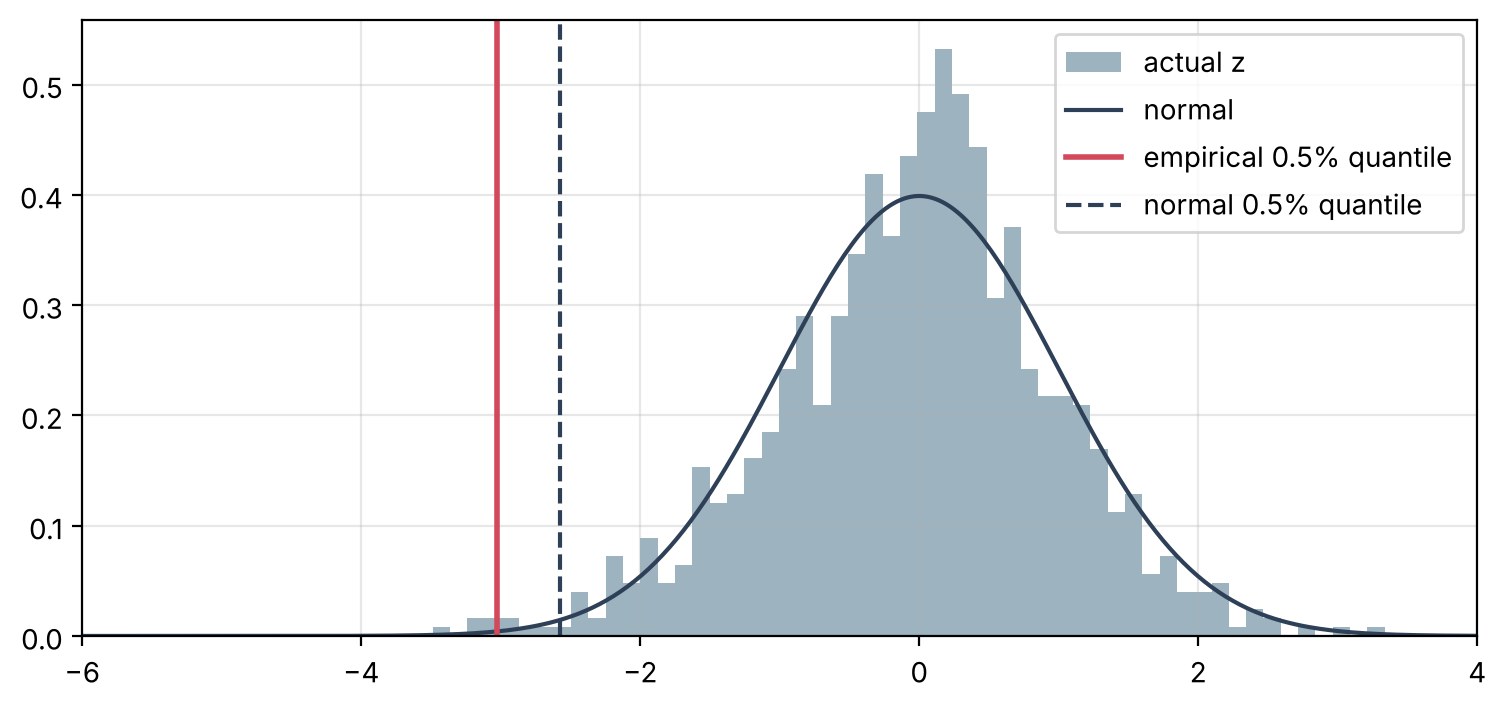

In [10]:
play(tail_shapes, examples=[{"alpha": 0.95}, {"alpha": 0.995}],
     alpha=(0.90, 0.995, 0.005))

## 第 5 步：亲手复现仓库的第一个正式预测（2009-12-23）

仓库的正式模型在 2009-12-23 这一天，用的正是上面这前 1000 天。我们按 FHS 的步骤手算，然后和 `reports/var_model_forecasts.csv.gz` 里存的结果对比。

In [11]:
sigma_next = gjr.next_sigma                          # 第 1 步：GJR 对 2009-12-23 的波动率预测
q99 = np.quantile(gjr.std_resid, 0.01)               # 第 2 步：1000 个 z 里数到 1%
manual = -gjr.mu - sigma_next * q99                  # 第 3 步：VaR = -(平均收益 + sigma x 分位数)
repo = fhs_var_es(gjr, gjr.std_resid, 0.99)[0]       # 仓库函数
stored = load_forecasts("FHS-GJR, W=1000 (正式模型)").loc["2009-12-23", "var_99"]

print(f"明天的波动率 sigma      = {sigma_next:.4%}")
print(f"z 的 1% 分位数          = {q99:.3f}")
print(f"手算 VaR 99%            = {manual:.6f}  = {money(manual * V)}")
print(f"仓库函数 fhs_var_es     = {repo:.6f}")
print(f"回测文件里存的          = {stored:.6f}")

明天的波动率 sigma      = 0.6607%
z 的 1% 分位数          = -2.531
手算 VaR 99%            = 0.016263  = $16,263
仓库函数 fhs_var_es     = 0.016263
回测文件里存的          = 0.016263


三个数一样。也就是说，仓库正式模型每天做的事情，就是你刚才这三行。之后每一天：σ 用 GJR 那一句话更新一次，z 的池子滚动加入最新的一天、丢掉最老的一天，每 21 天重新拟合一次参数。

## 第 6 步：把 16 年的预测画出来

下面是正式模型从 2009-12-23 到 2025-12-31 每天的 99% VaR（红线）和每天的实际亏损（灰点）。红叉是"亏损超过了 VaR"的日子，叫**突破**。

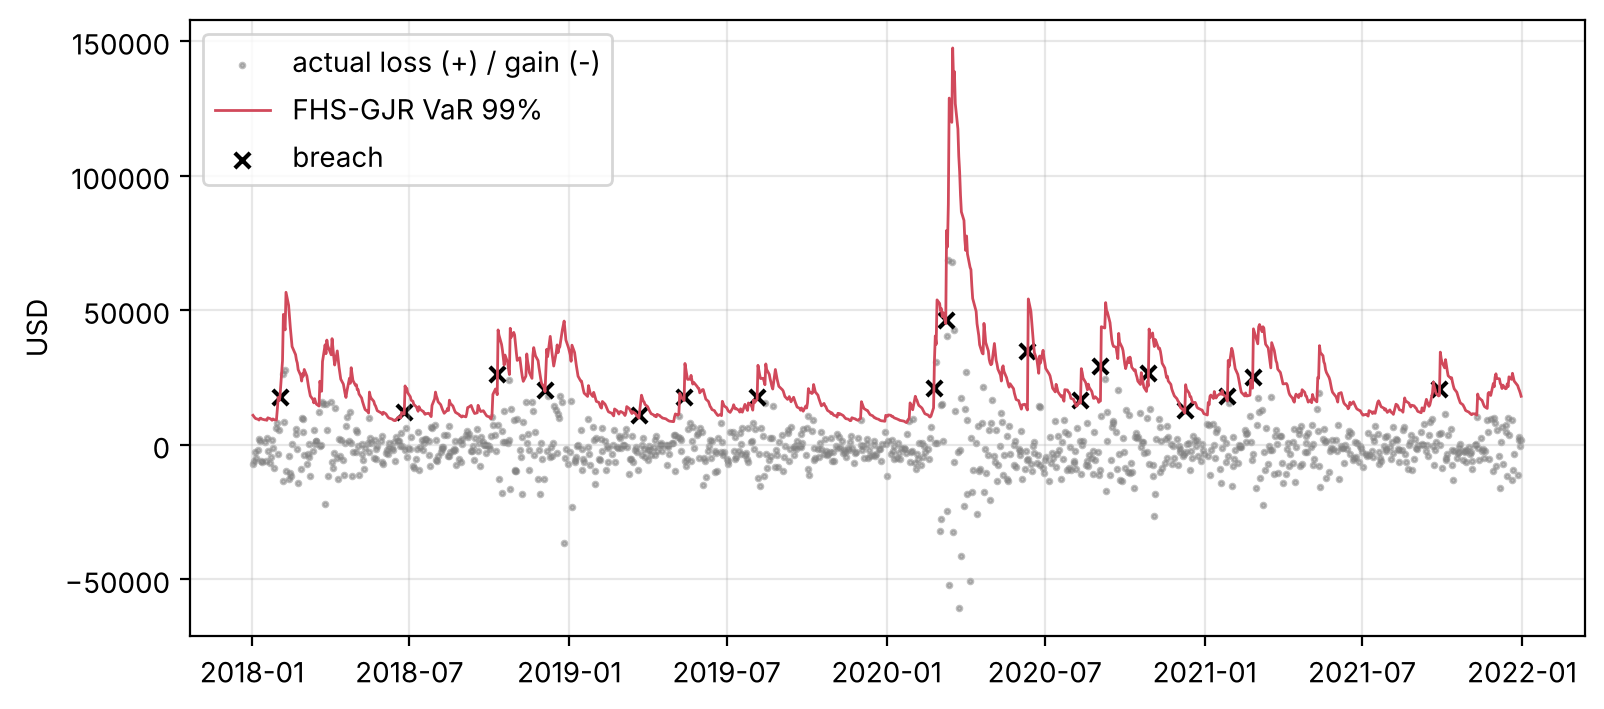

2018-2021：1008 天，突破 17 次，如果模型完全准确应该约 10.1 次


In [12]:
fc = load_forecasts("FHS-GJR, W=1000 (正式模型)")

def show_forecasts(year_from=2018, year_to=2021, alpha=0.99):
    k = int(round(alpha * 100))
    seg = fc.loc[str(year_from):str(year_to)]
    hit = breaches(seg, alpha).astype(bool)
    fig, ax = plt.subplots()
    ax.scatter(seg.index, -seg["realized"] * V, s=3, color="grey", alpha=0.5, label="actual loss (+) / gain (-)")
    ax.plot(seg.index, seg[f"var_{k}"] * V, color="#d1495b", lw=1, label=f"FHS-GJR VaR {alpha:.0%}")
    ax.scatter(seg.index[hit], -seg["realized"][hit] * V, marker="x", color="black", s=30, label="breach")
    ax.set_ylabel("USD"); ax.legend(loc="upper left"); plt.show()
    print(f"{year_from}-{year_to}：{len(seg)} 天，突破 {hit.sum()} 次，"
          f"如果模型完全准确应该约 {len(seg) * (1 - alpha):.1f} 次")

show_forecasts(2018, 2021)

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ year_from = 2009，year_to = 2013，alpha = 0.99


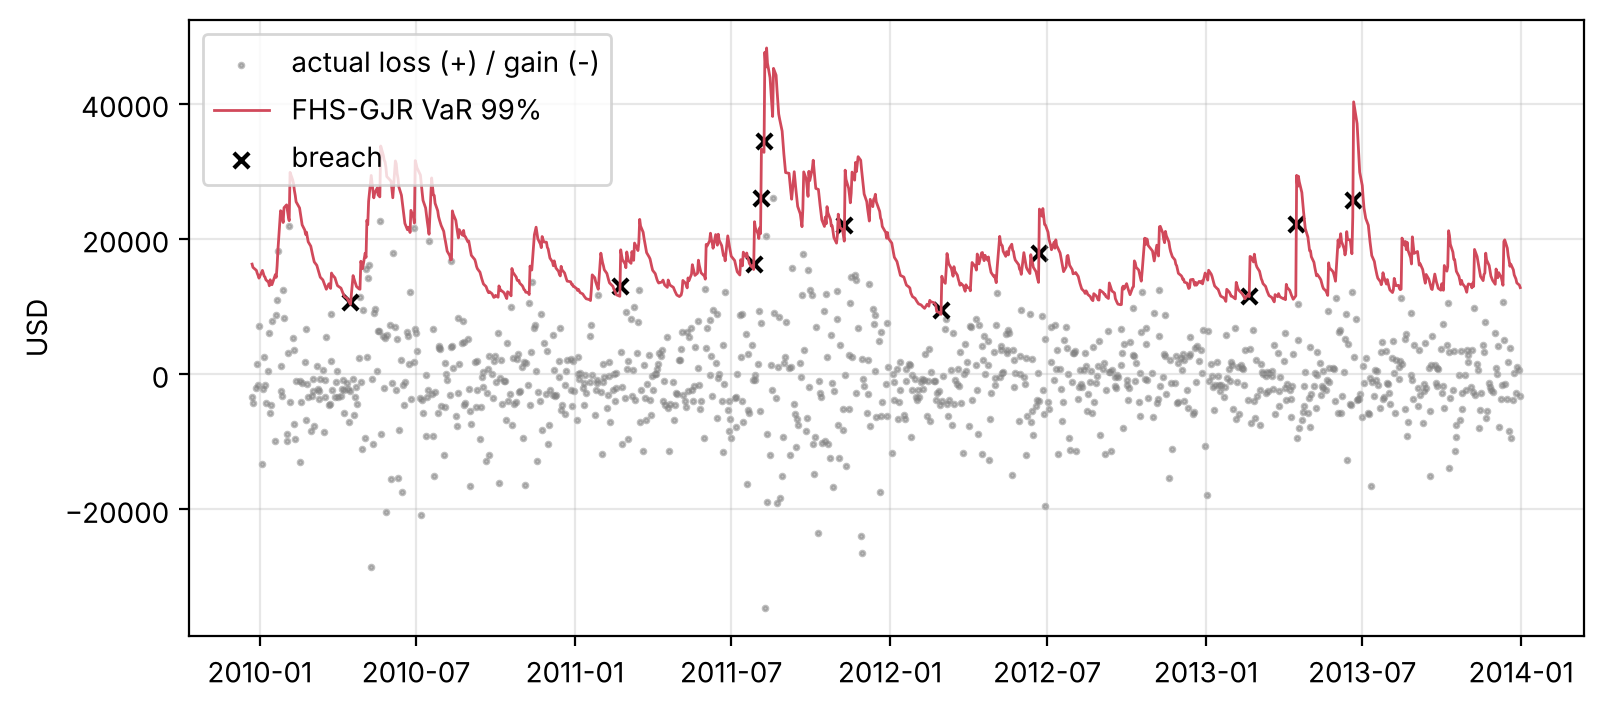

2009-2013：1012 天，突破 11 次，如果模型完全准确应该约 10.1 次

▶ year_from = 2022，year_to = 2025，alpha = 0.95


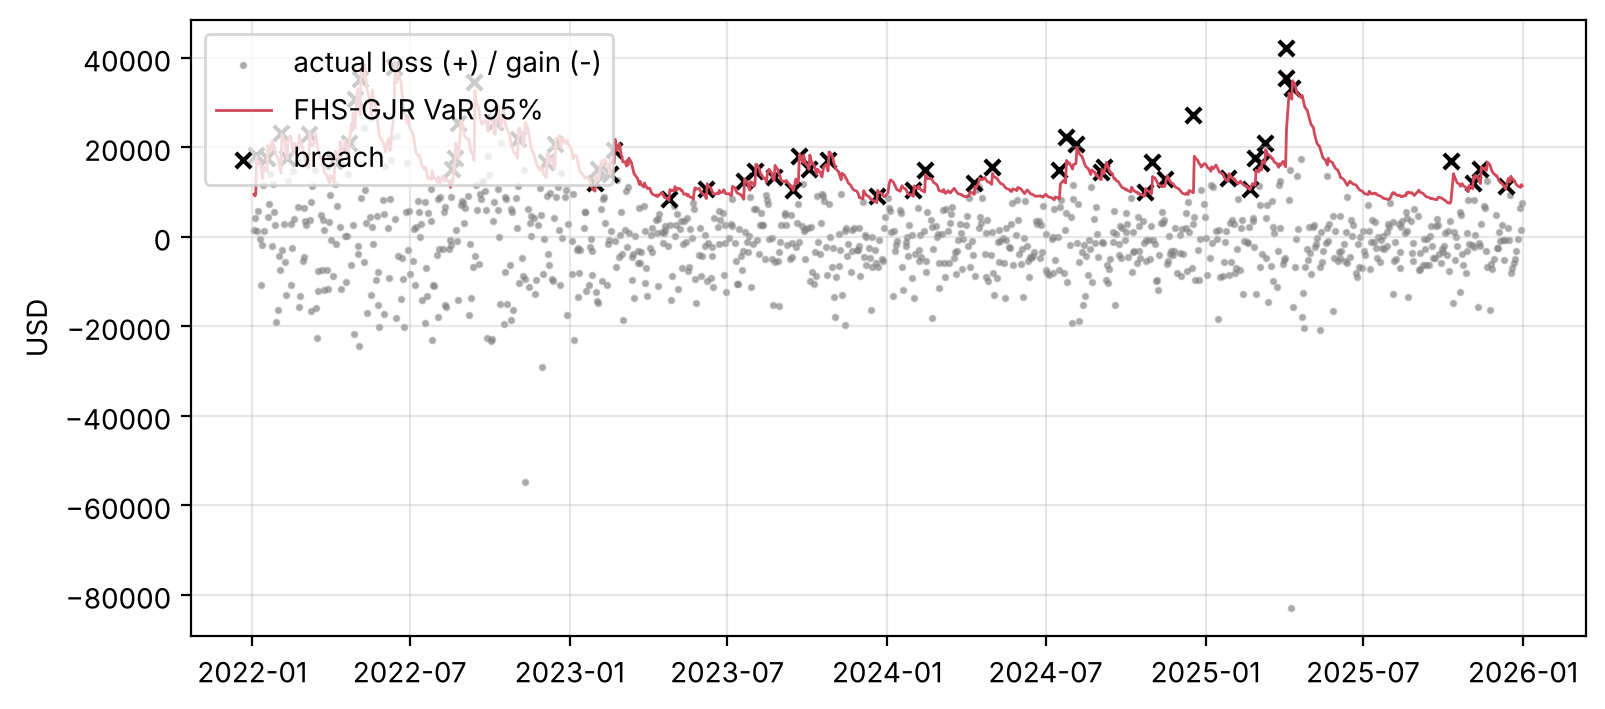

2022-2025：1003 天，突破 57 次，如果模型完全准确应该约 50.2 次


In [13]:
play(show_forecasts, examples=[{"year_from": 2009, "year_to": 2013, "alpha": 0.99}, {"year_from": 2022, "year_to": 2025, "alpha": 0.95}],
     year_from=(2009, 2025, 1), year_to=(2009, 2025, 1), alpha=[0.95, 0.99])

In [14]:
for a in (0.95, 0.99):
    h = breaches(fc, a)
    print(f"整个回测期 {len(fc)} 天，{a:.0%} VaR：实际突破 {h.sum()} 次，期望 {len(fc) * (1 - a):.1f} 次")

整个回测期 4030 天，95% VaR：实际突破 201 次，期望 201.5 次
整个回测期 4030 天，99% VaR：实际突破 47 次，期望 40.3 次


99% 的 VaR 突破 47 次（期望 40.3），95% 的突破 201 次（期望 201.5）。47 比 40.3 多一些，这算不算"模型有问题"？这正是第 4 本 notebook（回测）要回答的。

## 最后：公式

| 符号 | 意思 |
|---|---|
| $r_t$ | 第 $t$ 天收益率；$\mu$ 是平均日收益（很小） |
| $\varepsilon_t = r_t - \mu$ | 第 $t$ 天的"冲击" |
| $\sigma_t$ | 模型对第 $t$ 天波动率的估计 |
| $\mathbb{1}[\varepsilon_{t-1}<0]$ | 指示函数：昨天跌了就是 1，否则是 0 |
| $z_t = \varepsilon_t / \sigma_t$ | 标准化意外 |
| $\hat q_{1-\alpha}(z)$ | 过去 $W$ 天的 $z$ 排好后，第 $1-\alpha$ 位置的值（经验分位数） |

**GJR-GARCH(1,1)：**

$$\sigma_t^2 = \omega + \big(\alpha + \gamma\,\mathbb{1}[\varepsilon_{t-1}<0]\big)\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

**FHS 的 VaR 和 ES：**

$$\text{VaR}_{\alpha,t} = -\mu - \sigma_t\,\hat q_{1-\alpha}(z), \qquad \text{ES}_{\alpha,t} = -\mu + \sigma_t \times \big(z \text{ 最惨 } 1-\alpha \text{ 那部分的平均，取正}\big)$$

GJR 的参数用 Student-t 似然来估（所以叫"GJR-t 过滤器"），但算 VaR 时只用它给的 $\sigma_t$，尾巴形状用真实的 $z$。

**对应代码：** `src/mre/models/garch.py`（`fit_garch(..., vol="gjr")`、`GarchFit.next_variance`、`fhs_var_es`），`src/mre/backtest/rolling.py`（每天怎么滚动更新 σ 和 z 的池子）。

## 小练习

1. 如果某段时间 γ 估出来接近 0，GJR 和普通 GARCH 有什么区别？
2. FHS 用 W = 1000 天的 z 池子，比 W = 250 好在哪？差在哪？
3. 为什么 z 池子里的 z 必须只用"当天以前"的数据算？

<details><summary>点这里看参考答案</summary>

1. 几乎没区别，GJR 就退化成 GARCH。
2. 1000 个 z 里 1% 尾部大约有 10 个点，250 个 z 只有 2–3 个点，分位数会很不稳定；代价是 1000 天里的"意外形状"可能已经过时。仓库在 Phase 3b 里比较过不同 W，最后选了 1000。
3. 否则就是"用明天的答案来出今天的题"（前视偏差），回测结果会好看得不真实。仓库的 `tests/test_rolling.py` 专门检查了这一点：改动未来的数据，过去的预测必须一点都不变。
</details>